# Régression de consommation finale

Source commune : `output/cleaned_data.csv`, issue du notebook 1. Par défaut, le pipeline local est rechargé : ni recherche ni entraînement. Activer `IGNORE = False` pour la comparaison longue, ou `RUN_TRAINING = True` pour réentraîner et sauvegarder. Scores revérifiés le 29 octobre 2026 sans entraînement. Le test a servi à comparer les modèles : ces scores ne sont pas une validation externe. L'échantillon contient beaucoup de logements neufs ; il ne représente pas à lui seul le parc français.

Les scores historiques sont liés à la sauvegarde antérieure aux corrections géographiques ; ils ne valident pas le nouveau CSV. La comparaison future utilise une validation séparée.


**Table of contents**<a id='toc0_'></a>    
- [Preparing environment](#toc1_)    
- [Data import](#toc1_1_)    
- [Hyperparameters optimization for different models](#toc2_)    
  - [Splitting the train and test sets](#toc2_1_)    
  - [Model and parameters selection](#toc2_2_)    
  - [Grid search](#toc2_3_)    
  - [Adding XGBoost](#toc2_4_)    
  - [Optimizing XGBoost with penalization](#toc2_5_)    
- [Evaluating models](#toc3_)    
- [Final model training and saving](#toc4_)    

<!-- vscode-jupyter-toc-config
	numbering=false
	anchor=true
	flat=false
	minLevel=1
	maxLevel=6
	/vscode-jupyter-toc-config -->
<!-- THIS CELL WILL BE REPLACED ON TOC UPDATE. DO NOT WRITE YOUR TEXT IN THIS CELL -->

In [2]:
# <a id='toc1_'></a>[Preparing environment](#toc0_)

In [ ]:
from pathlib import Path
import os
import sys

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "pyproject.toml").exists() and (p / "MLmodels").is_dir()), None)
if ROOT is None:
    raise RuntimeError("Ouvrez le notebook depuis le dépôt App_Enedis.")
os.chdir(ROOT)
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
print("Racine du projet :", ROOT)

import joblib
import matplotlib.pyplot as plt
import mlflow
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.linear_model import LinearRegression, Ridge, Lasso, ElasticNet
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score,
)
from sklearn.model_selection import GridSearchCV, train_test_split
from sklearn.neighbors import KNeighborsRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor
from sklearn.inspection import permutation_importance
try:
    from xgboost import XGBRegressor
except ImportError:
    XGBRegressor = None

In [ ]:
IGNORE = True  # La recherche longue est facultative.
RUN_TRAINING = False  # Réutiliser le modèle sauvegardé par défaut.


# <a id='toc1_1_'></a>[Data import](#toc0_)

In [ ]:
from src.ml_workflow import load_data, reference_data_path
# Les scores historiques ne doivent pas être attribués au CSV corrigé.
DATA_FOR_EVALUATION = ROOT / "output/cleaned_data.csv" if RUN_TRAINING else reference_data_path()
print("Données utilisées :", DATA_FOR_EVALUATION)
print("Scores historiques avant correction géographique" if not RUN_TRAINING else "Nouvel entraînement explicite")
df = load_data(DATA_FOR_EVALUATION)


In [4]:
# Get rid of non feature columns
df = df.drop(
    columns=[
        "code_insee_ban",
        "code_departement_ban", 
        "code_postal_ban",
        "lat",
        "lon",
        "nom_commune_ban",
    ]
)

In [5]:
df

,cout_total_5_usages,type_energie_principale_chauffage,conso_5_usages_ef,surface_habitable_logement,nombre_niveau_logement,type_batiment,etiquette_dpe,age_batiment,zone_climatique,altitude_moyenne
0,946.3,Autre,9715.3,58.0,1.0,appartement,C,57.0,H1,35.0
1,724.5,Électricité,3970.4,30.0,1.0,appartement,D,79.0,H1,35.0
2,761.6,Électricité,3075.3,10.8,1.0,appartement,F,51.0,H1,35.0
3,946.8,Électricité,6803.0,70.0,1.0,appartement,C,78.0,H1,35.0
4,1246.0,Électricité,5571.8,34.7,1.0,appartement,E,392.0,H1,35.0
...,...,...,...,...,...,...,...,...,...,...
616052,879.2,Autre,5444.0,93.7,1.0,maison,B,0.0,H2,1026.0
616053,514.0,Autre,1878.9,89.9,1.0,maison,A,0.0,H2,1224.0
616054,518.0,Autre,1893.9,124.6,1.0,maison,A,0.0,H2,899.0
616055,568.3,Autre,2164.5,96.2,1.0,maison,A,0.0,H2,899.0


In [ ]:
# Caractéristiques du logement ; cible = consommation finale en kWh/an.
# Coût, étiquette DPE et consommations détaillées exclus des entrées.
quantitative_features = [
    "surface_habitable_logement",
    "nombre_niveau_logement", 
    "age_batiment",
    "altitude_moyenne",
]

qualitative_features = [
    "type_energie_principale_chauffage",
    "type_batiment", 
    "zone_climatique",
]

target = "conso_5_usages_ef"  # Regression target (numeric)

In [7]:
# Separating features and target.
X = df[quantitative_features + qualitative_features]
y = df[target]

In [8]:
print("Cible :", target)
print("Nombre de logements :", len(X))

print("\nValeurs manquantes dans les variables :")
print(X.isna().sum())

conso = pd.to_numeric(y, errors="coerce")
print("\nConsommations invalides :", (~np.isfinite(conso)).sum())
print("Consommations négatives :", (conso < 0).sum())
print("Consommations à zéro :", (conso == 0).sum())

Cible : conso_5_usages_ef
Nombre de logements : 616057

Valeurs manquantes dans les variables :
surface_habitable_logement           0
nombre_niveau_logement               0
age_batiment                         0
altitude_moyenne                     0
type_energie_principale_chauffage    0
type_batiment                        0
zone_climatique                      0
dtype: int64

Consommations invalides : 0
Consommations négatives : 0
Consommations à zéro : 1


In [9]:
df.loc[
    conso == 0,
    quantitative_features + qualitative_features + [target]
]

,surface_habitable_logement,nombre_niveau_logement,age_batiment,altitude_moyenne,type_energie_principale_chauffage,type_batiment,zone_climatique,conso_5_usages_ef
378782,119.6,1.0,0.0,128.0,Électricité,immeuble,H1,0.0


# <a id='toc2_'></a>[Hyperparameters optimization for different models](#toc0_)

## <a id='toc2_1_'></a>[Splitting the train and test sets](#toc0_)

In [10]:
# Splitting data into training and testing sets (70/30).
Xtrain, Xtest, ytrain, ytest = train_test_split(X, y, test_size=0.3, random_state=42)

In [11]:
print(len(Xtrain), len(Xtest))

431239 184818


In [12]:
ytrain.describe()

count    431239.000000
mean       7123.483157
std        7142.426619
min          27.000000
25%        2430.100000
50%        4390.400000
75%        9269.750000
max       92069.300000
Name: conso_5_usages_ef, dtype: float64

In [13]:
ytest.describe()

count    184818.000000
mean       7107.439499
std        7139.907302
min           0.000000
25%        2418.225000
50%        4383.700000
75%        9240.550000
max       85940.200000
Name: conso_5_usages_ef, dtype: float64

## <a id='toc2_2_'></a>[Model and parameters selection](#toc0_)

In [ ]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(),
    "Lasso": Lasso(),
    "ElasticNet": ElasticNet(),
    "Random Forest": RandomForestRegressor(random_state=42),
    "KNN": KNeighborsRegressor(),
    "Decision Tree": DecisionTreeRegressor(random_state=42),
}

param_grids = {
    "Linear Regression": {},  # No hyperparameters to tune
    "Ridge": {
        "model__alpha": [0.1, 1, 10, 100],
    },
    "Lasso": {
        "model__alpha": [0.1, 1, 10, 100],
    },
    "ElasticNet": {
        "model__alpha": [0.1, 1, 10],
        "model__l1_ratio": [0.1, 0.5, 0.9],
    },
    "Random Forest": {
        "model__n_estimators": [50, 100],
        "model__max_depth": [None, 5, 10],
        "model__min_samples_split": [2, 20],
    },
    "KNN": {
        "model__n_neighbors": [3, 5, 7],
        "model__weights": ["uniform", "distance"],
        "model__p": [1, 2],
    },
    "Decision Tree": {
        "model__max_depth": [None, 5, 10],
        "model__min_samples_split": [2, 20],
    },
}

# List of models that need feature scaling
enforce_scaling = ["Linear Regression", "Ridge", "Lasso", "ElasticNet", "KNN"]

## <a id='toc2_3_'></a>[Grid search](#toc0_)

In [ ]:
X_recherche = Xtrain.sample(n=min(30000, len(Xtrain)), random_state=42)
y_recherche = ytrain.loc[X_recherche.index]

print("Logements pour comparer les réglages :", len(X_recherche))

In [ ]:
if not IGNORE:
    # Creating an MLflow experiment.
    from uuid import uuid4
    from src.ml_workflow import fingerprint
    COMPARISON_ID = uuid4().hex
    DATA_SHA256 = fingerprint(DATA_FOR_EVALUATION)
    mlflow.set_experiment("Regression consommation finale")

    # Boucle sur les modèles
    for name, model in models.items():
        # MLflow run
        with mlflow.start_run(run_name=name):
            mlflow.set_tags({"comparison_id": COMPARISON_ID,
                             "target": target, "data_sha256": DATA_SHA256})
            print("Training model:", name)

            # Standardization for non trees models.
            if name in enforce_scaling:
                preprocessor = ColumnTransformer(
                    transformers=[
                        (
                            "scaler",
                            StandardScaler(),
                            quantitative_features,
                        ),  # Standardize only quantitatives.
                        (
                            "encoder",
                            OneHotEncoder(handle_unknown="ignore"),
                            qualitative_features,
                        ),  # OneHot encoding for qualitatives.
                    ]
                )

            else:
                preprocessor = ColumnTransformer(
                    transformers=[
    ("numeric", "passthrough", quantitative_features),
    ("encoder", OneHotEncoder(handle_unknown="ignore"), qualitative_features),
]
                )

            pipeline = Pipeline(
                steps=[("preprocessor", preprocessor), ("model", models[name])]
            )

            # GridSearchCV - using neg_mean_absolute_error for regression
            if param_grids[name]:  # Only do grid search if parameters exist
                grid = GridSearchCV(
                    pipeline,
                    param_grids[name],
                    cv=3,
                    scoring="neg_mean_absolute_error",
                    n_jobs=-1,
                )
                grid.fit(X_recherche, y_recherche)
                best_estimator = grid.best_estimator_
                best_params = grid.best_params_
                best_score = grid.best_score_
            else:
                # No hyperparameters to tune, just fit the pipeline
                pipeline.fit(X_recherche, y_recherche)
                best_estimator = pipeline
                best_params = {}
                best_score = None

            # Predictions and evaluation
            ypred = best_estimator.predict(Xtest)
            mae = mean_absolute_error(ytest, ypred)
            rmse = np.sqrt(mean_squared_error(ytest, ypred))
            r2 = r2_score(ytest, ypred)

            # Logging MLflow
            mlflow.log_params(best_params)  # Hyperparameters
            if best_score is not None:
                mlflow.log_metric("best_cv_score", -best_score)  # Convert back to positive MAE
            mlflow.log_metric("test_mae", float(mae))
            mlflow.log_metric("test_rmse", float(rmse))
            mlflow.log_metric("test_r2", float(r2))

In [ ]:
if not IGNORE:
    resultats = mlflow.search_runs(
        experiment_names=["Regression consommation finale"],
        filter_string=f"tags.comparison_id = '{COMPARISON_ID}'",
        order_by=["start_time DESC"]
    )
    
    tableau = resultats[
        [
            "tags.mlflow.runName",
            "metrics.test_mae",
            "metrics.test_rmse",
            "metrics.test_r2",
        ]
    ]  # Uniquement les essais de cette exécution et de cette cible.
    
    display(tableau.sort_values("metrics.test_mae"))


In [ ]:
if not IGNORE:
    runs_rf = resultats[
        resultats["tags.mlflow.runName"] == "Random Forest"
    ]
    
    display(
        runs_rf[
            [
                "params.model__n_estimators",
                "params.model__max_depth",
                "params.model__min_samples_split",
            ]
        ].head(1)
    )


---

# <a id='toc3_'></a>[Evaluating models](#toc0_)

## Évaluation des modèles

Les réglages sont recherchés par validation croisée sur un échantillon
de 30 000 logements du jeu d’entraînement.

Sept modèles sont comparés. Le Random Forest obtient la plus faible
MAE sur le jeu de test dans cette comparaison.

Il est ensuite entraîné sur les 431 239 logements d’entraînement,
avec les réglages retenus.

Résultats sur les 184 818 logements de test :
- MAE : 2 121,45 kWh/an
- RMSE : 3 954,70 kWh/an
- R² : 0,6932

Le jeu de test ayant aussi servi à comparer les modèles, ces scores
ne constituent pas une évaluation finale totalement indépendante.

# <a id='toc4_'></a>[Final model training and saving](#toc0_)

## Final training

In [ ]:
# Random Forest à évaluer sur la consommation.
# On vérifiera ses résultats avant de le retenir.

modele_regression = RandomForestRegressor(
    n_estimators=100,
    max_depth=10,
    min_samples_split=20,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

Xtrain, Xtest, ytrain, ytest = train_test_split(
    X, y,
    test_size=0.3,
    random_state=42
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", "passthrough", quantitative_features),
        (
            "encoder",
            OneHotEncoder(handle_unknown="ignore"),
            qualitative_features
        ),
    ]
)

pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", modele_regression),
    ]
)

if RUN_TRAINING:
    pipeline.fit(Xtrain, ytrain)
else:
    pipeline = joblib.load(ROOT / 'MLmodels/pipeline_random_forest_consommation.pkl')
predictions = pipeline.predict(Xtest)

In [21]:
print("MAE :", round(mean_absolute_error(ytest, predictions), 2))
print("RMSE :", round(np.sqrt(mean_squared_error(ytest, predictions)), 2))
print("R² :", round(r2_score(ytest, predictions), 4))

MAE : 2121.45
RMSE : 3954.7
R² : 0.6932


In [23]:
# get the list of features after preprocessing.
encoder = pipeline.named_steps["preprocessor"].named_transformers_["encoder"]
encoder_feature_names = encoder.get_feature_names_out(qualitative_features)
preprocessed_feature_names = quantitative_features + list(encoder_feature_names)

## Performance metrics and residuals analysis

Test MAE: 2121.45
Test RMSE: 3954.70
Test R²: 0.6932


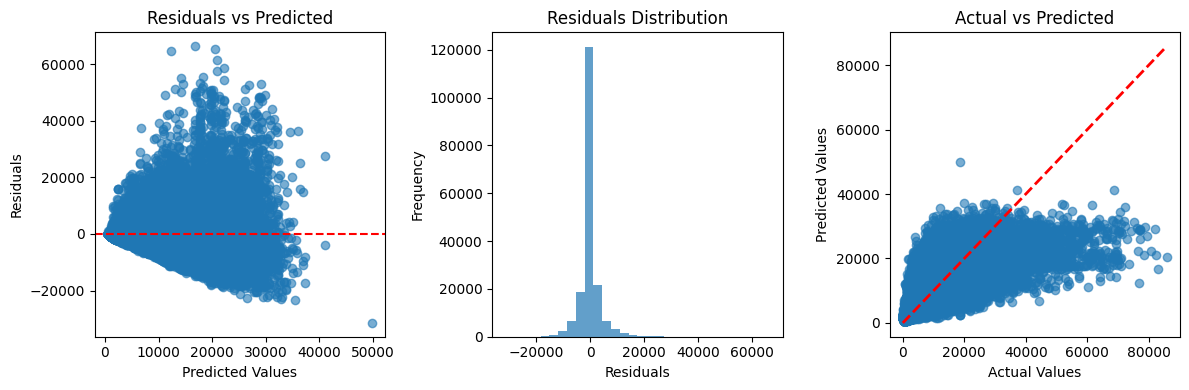

In [26]:
# Performance metrics
mae = mean_absolute_error(ytest, predictions)
rmse = np.sqrt(mean_squared_error(ytest, predictions))
r2 = r2_score(ytest, predictions)

print(f"Test MAE: {mae:.2f}")
print(f"Test RMSE: {rmse:.2f}")
print(f"Test R²: {r2:.4f}")

# Residuals analysis
residuals = ytest - predictions
plt.figure(figsize=(12, 4))

# Residuals vs Predicted
plt.subplot(1, 3, 1)
plt.scatter(predictions, residuals, alpha=0.6)
plt.axhline(y=0, color='r', linestyle='--')
plt.xlabel('Predicted Values')
plt.ylabel('Residuals')
plt.title('Residuals vs Predicted')

# Residuals distribution
plt.subplot(1, 3, 2)
plt.hist(residuals, bins=30, alpha=0.7)
plt.xlabel('Residuals')
plt.ylabel('Frequency')
plt.title('Residuals Distribution')

# Actual vs Predicted
plt.subplot(1, 3, 3)
plt.scatter(ytest, predictions, alpha=0.6)
plt.plot([ytest.min(), ytest.max()], [ytest.min(), ytest.max()], 'r--', lw=2)
plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted')

plt.tight_layout()
plt.show()

## Saving the pipeline

In [ ]:
if RUN_TRAINING:
    from pathlib import Path
    
    Path("MLmodels").mkdir(exist_ok=True)
    
    joblib.dump(
        pipeline,
        "MLmodels/pipeline_random_forest_consommation.pkl",
        compress=3
    )


In [ ]:
if RUN_TRAINING:
    joblib.dump(
        {
            "quantitative_features": quantitative_features,
            "qualitative_features": qualitative_features,
            "target": target,
        },
        "MLmodels/features_target_columns_consommation.pkl"
    )


In [24]:
modele_recharge = joblib.load(
    "MLmodels/pipeline_random_forest_consommation.pkl"
)

infos = joblib.load(
    "MLmodels/features_target_columns_consommation.pkl"
)

print("Cible :", infos["target"])
print("Modèle :", type(modele_recharge.named_steps["model"]).__name__)

np.testing.assert_allclose(
    modele_recharge.predict(Xtest.head(3)),
    pipeline.predict(Xtest.head(3))
)

print("Vérification réussie : prédictions identiques après rechargement.")

Cible : conso_5_usages_ef
Modèle : RandomForestRegressor
Vérification réussie : prédictions identiques après rechargement.


## Features importance

### Feature importance extraction from the model

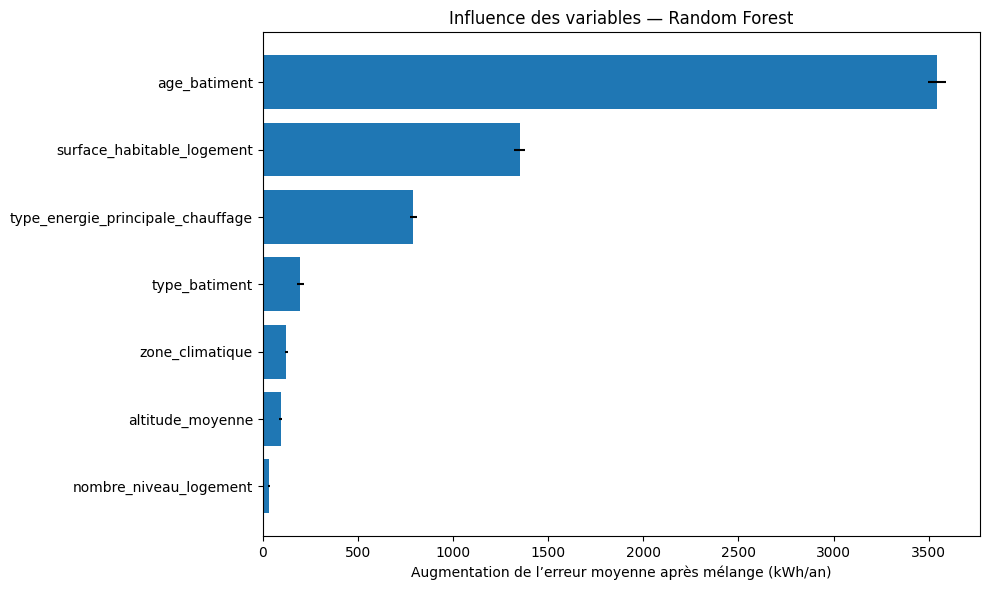

,Variable,Importance,Ecart_type
2,age_batiment,3543.248066,46.658473
0,surface_habitable_logement,1351.090429,28.143674
4,type_energie_principale_chauffage,792.268412,17.935705
5,type_batiment,198.208134,20.278434
6,zone_climatique,124.947154,6.577557
3,altitude_moyenne,94.407482,8.873581
1,nombre_niveau_logement,33.653202,4.922992


In [25]:
from sklearn.inspection import permutation_importance

# Échantillon du jeu de test pour analyser les variables.
X_analyse = Xtest.sample(n=min(5000, len(Xtest)), random_state=42)
y_analyse = ytest.loc[X_analyse.index]

perm_importance = permutation_importance(
    pipeline,
    X_analyse,
    y_analyse,
    scoring="neg_mean_absolute_error",
    n_repeats=5,
    random_state=42,
    n_jobs=1
)

df_feature_importances = pd.DataFrame({
    "Variable": X_analyse.columns,
    "Importance": perm_importance.importances_mean,
    "Ecart_type": perm_importance.importances_std
}).sort_values("Importance", ascending=False)

plt.figure(figsize=(10, 6))
plt.barh(
    df_feature_importances["Variable"],
    df_feature_importances["Importance"],
    xerr=df_feature_importances["Ecart_type"]
)
plt.xlabel("Augmentation de l’erreur moyenne après mélange (kWh/an)")
plt.title("Influence des variables — Random Forest")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

display(df_feature_importances)